# 01 · Players & career outcomes

Files: `players.csv`, `player_career_successes.csv`.

**Questions:** Who is in the 510-player cohort (position, draft class, college)? How are draft slot and career outcomes related? How sparse are the accolades?

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from utils import *
set_style()
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 160)

In [2]:
players = load_csv("players", parse_dates=["birth_date"])
career = load_csv("player_career_successes")
print(players.shape, career.shape)
assert players.nfl_id.is_unique and career.nfl_id.is_unique
print("ids match:", set(players.nfl_id) == set(career.nfl_id))
players.head()

(510, 10) (510, 9)
ids match: True


,nfl_id,display_name,draft_year,nfl_position,birth_date,college_name,college_conference,draft_round,draft_pick_within_round,draft_overall_pick
0,55867,Will Anderson,2023,DE,2001-09-02,Alabama,Southeastern Conference,1.0,3.0,3.0
1,55870,Paris Johnson,2023,T,2001-07-31,Ohio State,Big Ten Conference,1.0,6.0,6.0
2,55874,Darnell Wright,2023,T,2001-08-10,Tennessee,Southeastern Conference,1.0,10.0,10.0
3,55875,Peter Skoronski,2023,G,2001-07-31,Northwestern,Big Ten Conference,1.0,11.0,11.0
4,55877,Lukas Van Ness,2023,DE,2001-07-06,Iowa,Big Ten Conference,1.0,13.0,13.0


## Missingness

In [3]:
missingness(players)

,n_missing,pct_missing,dtype
draft_round,127,24.9,float64
draft_pick_within_round,127,24.9,float64
draft_overall_pick,127,24.9,float64
nfl_id,0,0.0,int64
display_name,0,0.0,str
draft_year,0,0.0,int64
nfl_position,0,0.0,str
birth_date,0,0.0,datetime64[us]
college_name,0,0.0,str
college_conference,0,0.0,str


Nulls in the draft columns should correspond exactly to undrafted free agents (UDFAs).

In [4]:
players["udfa"] = players.draft_overall_pick.isna()
print(players.groupby("draft_year").udfa.agg(["sum", "mean", "size"]))
assert (players.draft_round.isna() == players.udfa).all()

            sum      mean  size
draft_year                     
2023         44  0.275000   160
2024         36  0.203390   177
2025         47  0.271676   173


## Cohort composition

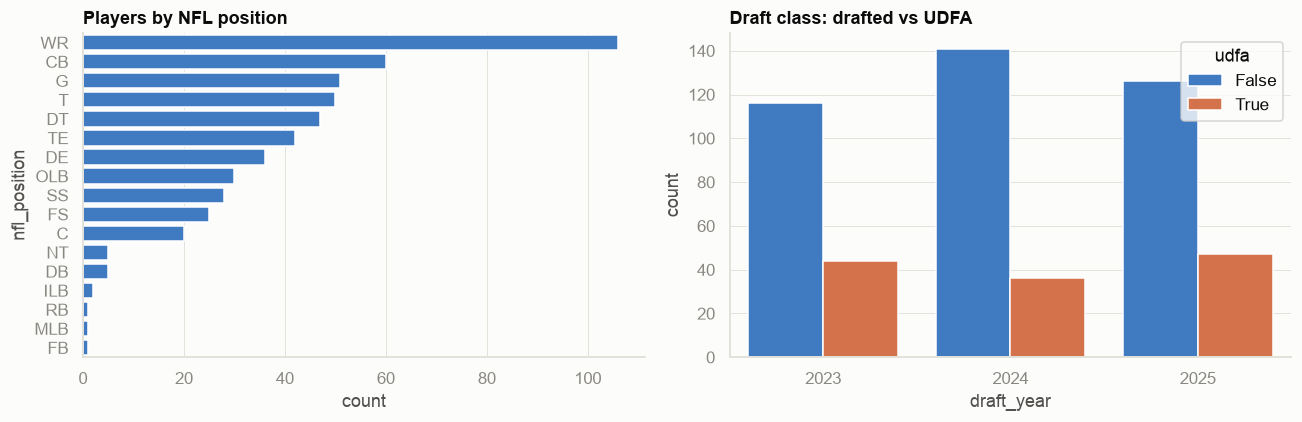

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order = players.nfl_position.value_counts().index
sns.countplot(data=players, y="nfl_position", order=order, color=PALETTE[0], ax=axes[0]); axes[0].set_title("Players by NFL position")
sns.countplot(data=players, x="draft_year", hue="udfa", ax=axes[1], palette=[PALETTE[0], PALETTE[1]]); axes[1].set_title("Draft class: drafted vs UDFA")
plt.tight_layout(); savefig(fig, "01_composition")

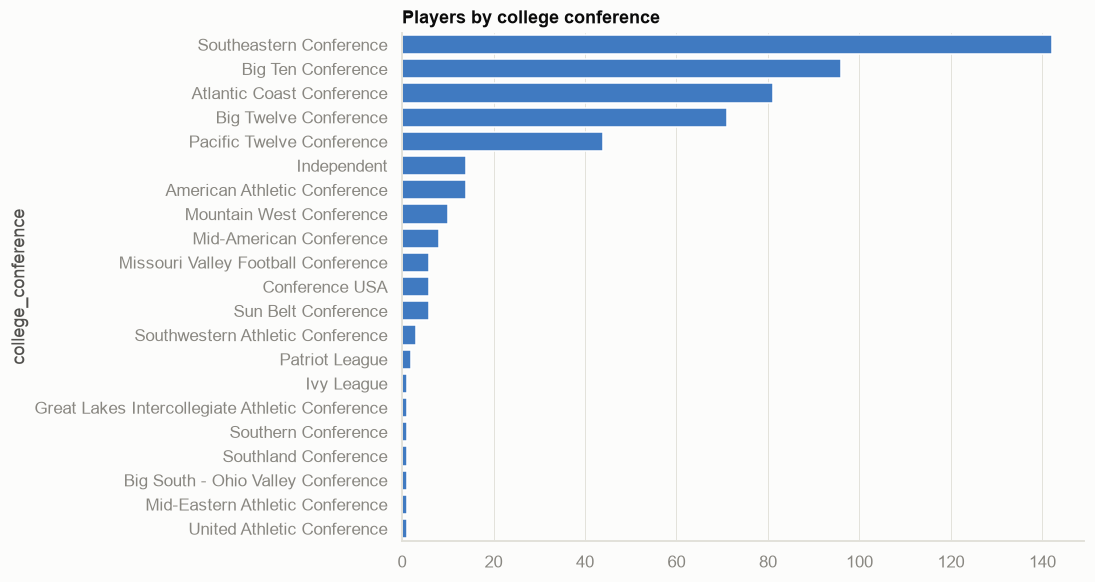

In [6]:
fig, ax = plt.subplots(figsize=(8, 6))
conf = players.college_conference.value_counts()
sns.barplot(x=conf.values, y=conf.index, color=PALETTE[0], ax=ax); ax.set_title("Players by college conference")
savefig(fig, "01_conference")

count    510.000000
mean      22.942320
std        1.006107
min       20.640657
25%       22.270363
50%       23.015743
75%       23.563313
max       26.368241
Name: age_at_draft, dtype: float64

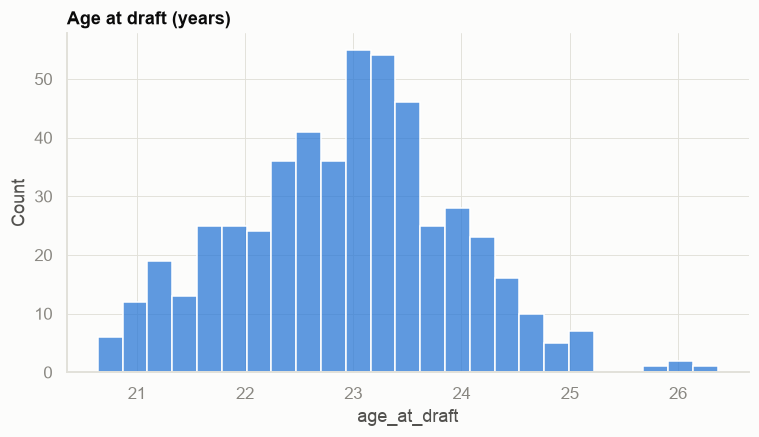

In [7]:
players["age_at_draft"] = (pd.to_datetime(players.draft_year.astype(str) + "-04-25") - players.birth_date).dt.days / 365.25
fig, ax = plt.subplots()
sns.histplot(players.age_at_draft, bins=25, color=PALETTE[0], ax=ax); ax.set_title("Age at draft (years)")
players.age_at_draft.describe()

## Draft capital

draft_round
1.0    38
2.0    59
3.0    59
4.0    59
5.0    62
6.0    50
7.0    56
Name: count, dtype: int64


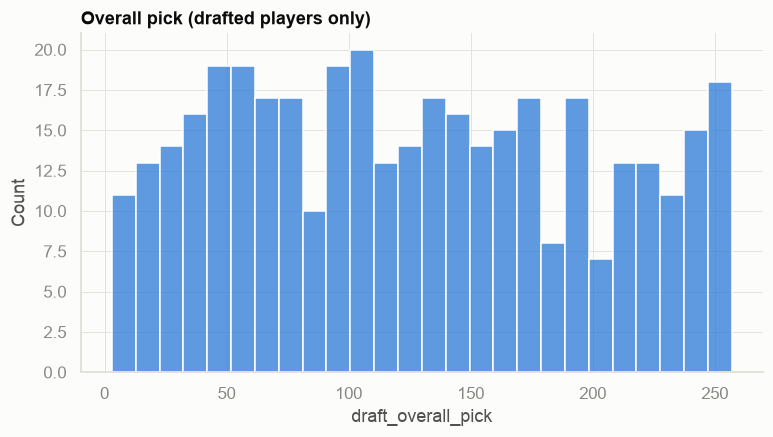

In [8]:
drafted = players[~players.udfa]
fig, ax = plt.subplots()
sns.histplot(drafted.draft_overall_pick, bins=26, color=PALETTE[0], ax=ax); ax.set_title("Overall pick (drafted players only)")
print(drafted.draft_round.value_counts().sort_index())

## Career outcomes

In [9]:
df = players.merge(career, on="nfl_id")
df["total_snaps"] = df.career_offensive_snaps + df.career_defensive_snaps + df.career_special_teams_snaps
describe_num(career.drop(columns="nfl_id"))

,count,mean,std,min,1%,25%,50%,75%,99%,max
career_offensive_snaps,510.0,327.415686,632.400084,0.0,0.0,0.00,0.0,361.75,2781.84,3303.0
career_defensive_snaps,510.0,234.307843,492.121894,0.0,0.0,0.00,0.0,220.50,2134.68,2666.0
career_special_teams_snaps,510.0,113.503922,156.194148,0.0,0.0,5.00,53.0,147.75,689.55,957.0
career_games_active,510.0,21.721569,16.285063,0.0,0.0,6.25,17.0,34.00,51.00,51.0
career_games_started,510.0,7.852941,11.466015,0.0,0.0,0.00,2.0,12.00,47.64,50.0
ap_all_pro_1st_team,510.0,0.011765,0.107931,0.0,0.0,0.00,0.0,0.00,0.91,1.0
ap_all_pro_2nd_team,510.0,0.003922,0.062561,0.0,0.0,0.00,0.0,0.00,0.00,1.0
pro_bowl_original_ballot,510.0,0.027451,0.196310,0.0,0.0,0.00,0.0,0.00,1.00,2.0


In [10]:
acc = ["ap_all_pro_1st_team", "ap_all_pro_2nd_team", "pro_bowl_original_ballot"]
print("share of players with >=1:"); print((career[acc] > 0).mean().round(3))
print("no snaps at all:", (df.total_snaps == 0).sum(), "| zero games active:", (df.career_games_active == 0).sum())

share of players with >=1:
ap_all_pro_1st_team         0.012
ap_all_pro_2nd_team         0.004
pro_bowl_original_ballot    0.022
dtype: float64
no snaps at all: 95 | zero games active: 88


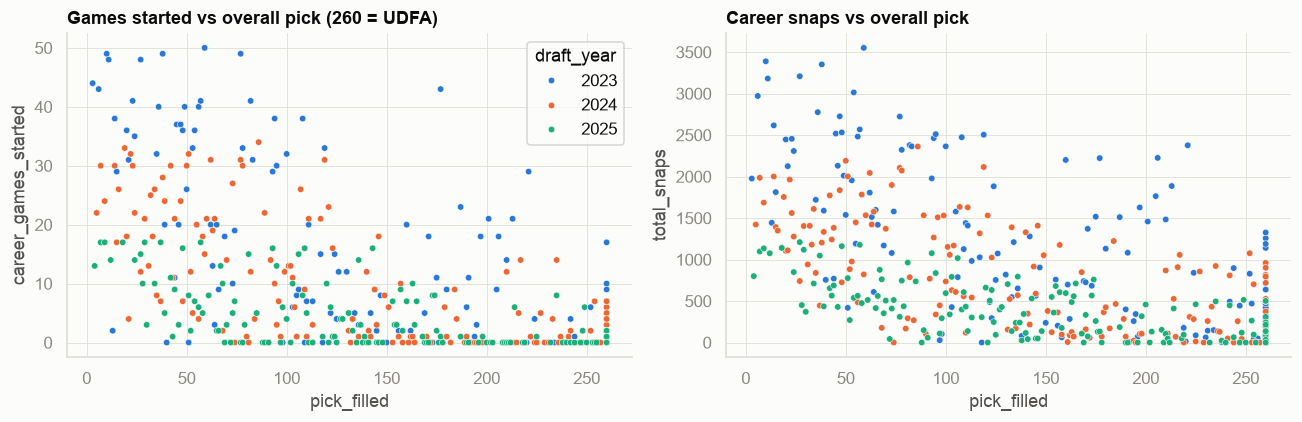

In [11]:
df["pick_filled"] = df.draft_overall_pick.fillna(260)   # UDFAs plotted past the last pick
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=df, x="pick_filled", y="career_games_started", hue="draft_year", palette=PALETTE[:3], s=18, ax=axes[0]); axes[0].set_title("Games started vs overall pick (260 = UDFA)")
sns.scatterplot(data=df, x="pick_filled", y="total_snaps", hue="draft_year", palette=PALETTE[:3], s=18, legend=False, ax=axes[1]); axes[1].set_title("Career snaps vs overall pick")
plt.tight_layout(); savefig(fig, "01_pick_vs_outcomes")

,career_games_active,career_games_started,total_snaps
draft_year,,,
2023,40.5,5.0,789.5
2024,26.0,2.0,498.0
2025,17.0,0.0,194.0


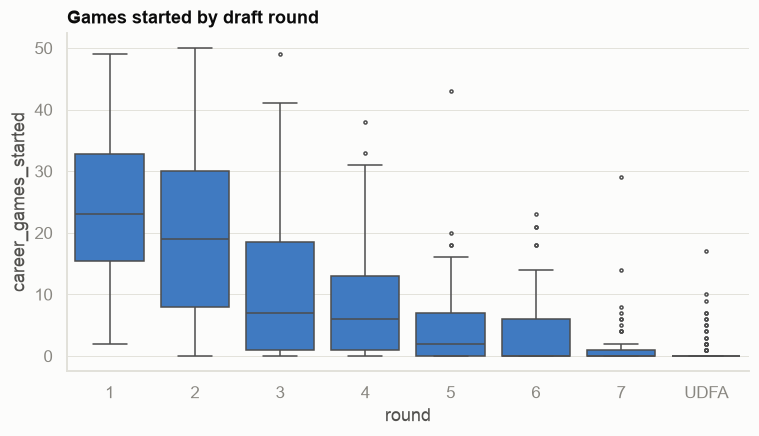

In [12]:
df["round"] = df.draft_round.fillna(8).astype(int).replace({8: "UDFA"}).astype(str)
fig, ax = plt.subplots()
sns.boxplot(data=df, x="round", y="career_games_started", order=[str(i) for i in range(1, 8)] + ["UDFA"], color=PALETTE[0], fliersize=2, linewidth=1, ax=ax)
ax.set_title("Games started by draft round")
df.groupby("draft_year")[["career_games_active", "career_games_started", "total_snaps"]].median()

**Note:** later draft classes have had less time to accumulate games, so career totals are **not comparable across `draft_year`** without exposure adjustment (e.g. per-game rates).

## Findings / follow-ups
- Fill in after reviewing outputs.